In [1]:
# conda env 'at3d'

import pymap3d as pm
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import at3d
import netCDF4 as nc
import os
from scipy.interpolate import griddata

In [2]:
## INPUT
# RT Grid
rte_grid_file = '../intermediate_data/RTG_1400.nc'
# CTH
cth_file = '../intermediate_data/MISR_CTH_CAMP2Ex_RF17_default.nc'
# Carved Volume
carved_vol_file = '../intermediate_data/CARVED_VOL_th00.nc'
# LCL
lcl = 0.4

## OUTPUT
out_file = '../intermediate_data/CVM_default.nc'

In [3]:
rte_grid = xr.load_dataset(rte_grid_file)
cloud_data = xr.load_dataset(cth_file)
carved_volume = xr.load_dataset(carved_vol_file)

In [4]:
wgs84 = pm.Ellipsoid('wgs84')
e, n, u = pm.geodetic2enu(
    cloud_data.lat1100.data,
    cloud_data.lon1100.data,
    cloud_data.cth.data,
    cloud_data.center_lat.data,
    cloud_data.center_lon.data,
    0.0,
    ell=wgs84,
    deg=True
)
cloud_data['E'] = (['y1100', 'x1100'], e/1000)
cloud_data['N'] = (['y1100', 'x1100'], n/1000)
cloud_data['z_cloud'] = (['y1100', 'x1100'], u/1000)

# Horizontal shift to place origin at the corner of the rte grid (maintain centering)
cloud_data['E'] = cloud_data.E + np.max(rte_grid.x.data)/2
cloud_data['E'] = cloud_data.E.assign_attrs(units='km')
cloud_data['N'] = cloud_data.N + np.max(rte_grid.y.data)/2
cloud_data['N'] = cloud_data.N.assign_attrs(units='km')

In [5]:
# Create the new grid
grid_x, grid_y = np.meshgrid(rte_grid.x.data, rte_grid.y.data, indexing='ij')

# Flatten the original grid and data
points = np.array([cloud_data.E.data.flatten(), cloud_data.N.data.flatten()]).T
values = cloud_data.z_cloud.data.flatten()

# Mask out NaN values
mask = ~np.isnan(values)
points = points[mask]
values = values[mask]

# Interpolate the data onto the new grid
cth_interp = griddata(points, values, (grid_x, grid_y), method='linear')

In [6]:
cth_on_rte_grid = rte_grid.z.data[np.searchsorted(rte_grid.z.data, cth_interp, side='right')]

In [7]:
cloud_data

<xarray.Dataset>
Dimensions:     (y1100: 48, x1100: 48)
Dimensions without coordinates: y1100, x1100
Data variables:
    cth         (y1100, x1100) float32 570.0 590.0 575.0 ... 731.0 735.0 737.0
    cm          (y1100, x1100) float32 4.0 3.0 3.0 4.0 4.0 ... 3.0 1.0 2.0 2.0
    squi        (y1100, x1100) float32 91.0 84.0 76.0 94.0 ... 96.0 88.0 92.0
    lat1100     (y1100, x1100) float64 19.52 19.52 19.52 ... 19.02 19.01 19.01
    lon1100     (y1100, x1100) float64 119.5 119.5 119.5 ... 119.9 119.9 119.9
    center_lat  float64 19.27
    center_lon  float64 119.7
    E           (y1100, x1100) float64 -14.78 -13.69 -12.59 ... 31.29 32.38
    N           (y1100, x1100) float64 36.73 36.64 36.55 ... -19.04 -19.14
    z_cloud     (y1100, x1100) float64 0.4649 0.4893 0.4784 ... 0.6343 0.6319
Attributes:
    orbit:    105254
    path:     117
    blocks:   [75 75]

Text(0.5, 1.0, 'CTH on RTE Grid')

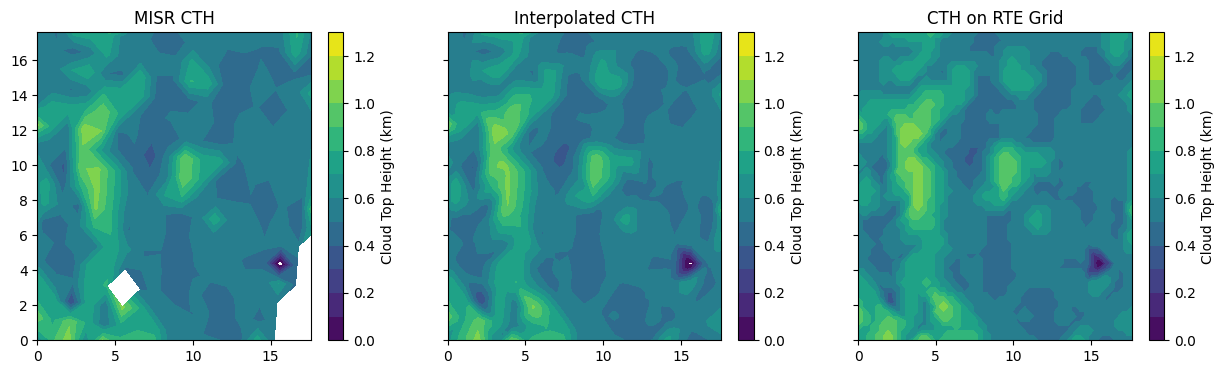

In [8]:
levels = np.arange(0, 1.4, 0.1)
f, ax = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
c0 = ax[0].contourf(cloud_data.E.data, cloud_data.N.data, cloud_data.z_cloud.data, levels=levels)
plt.colorbar(c0, ax=ax[0], label='Cloud Top Height (km)')
ax[0].set_title('MISR CTH')
c1 = ax[1].contourf(grid_x, grid_y, cth_interp, levels=levels)
plt.colorbar(c1, ax=ax[1], label='Cloud Top Height (km)')
ax[1].set_title('Interpolated CTH')
c2 = ax[2].contourf(grid_x, grid_y, cth_on_rte_grid, levels=levels)
plt.colorbar(c2, ax=ax[2], label='Cloud Top Height (km)')
ax[2].set_title('CTH on RTE Grid')

In [9]:
cth_on_rte_grid = np.expand_dims(cth_on_rte_grid, axis=-1)
cth_mask = (rte_grid.z.data <= cth_on_rte_grid).astype(int)
rte_grid['cth_mask'] = (['x', 'y', 'z'], cth_mask)

In [10]:
lcl_on_rte_grid = rte_grid.z.data[np.searchsorted(rte_grid.z.data, lcl, side='right') - 1]
lcl_mask = np.zeros((rte_grid.dims['x'], rte_grid.dims['y'], rte_grid.dims['z']))
lcl_mask[:,:,rte_grid.z.data >= lcl_on_rte_grid] = 1
rte_grid['lcl_mask'] = (['x', 'y', 'z'], lcl_mask)

In [11]:
rte_grid['carved_mask'] = (['x', 'y', 'z'], carved_volume.mask.data)

In [12]:
rbg_mask = np.zeros((rte_grid.dims['y'], rte_grid.dims['x'], rte_grid.dims['z'], 3))
rbg_mask[:,:,:,0] = rte_grid.cth_mask # Red
rbg_mask[:,:,:,1] = rte_grid.lcl_mask # Green
rbg_mask[:,:,:,2] = rte_grid.carved_mask # Blue
rte_grid['rbg_mask'] = (['x', 'y', 'z', 'rgb'], rbg_mask)

In [13]:
mask = np.logical_and(rte_grid.cth_mask.data, rte_grid.lcl_mask.data)
mask = np.logical_and(rte_grid.carved_mask.data, mask)
mask[0,:,:] = mask[-1,:,:] = mask[:,0,:] = mask[:,-1,:] = 0.0
rte_grid['cloud_volume_mask'] = (['x', 'y', 'z'], mask)
rte_grid.to_netcdf(out_file)

In [14]:
print('Number of free parameters: {}'.format(np.sum(rte_grid.cloud_volume_mask.data)))

Number of free parameters: 11587


In [15]:
rte_grid['cfba'] = rte_grid.cloud_volume_mask.sum(('x','y')) / (rte_grid.dims['x'] * rte_grid.dims['y'])

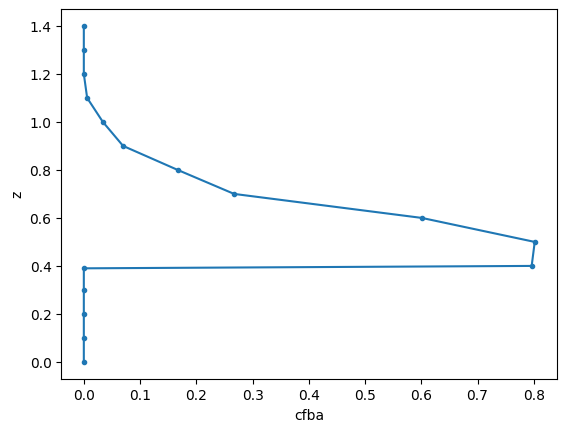

In [16]:
rte_grid.cfba.plot(y='z', marker='.')

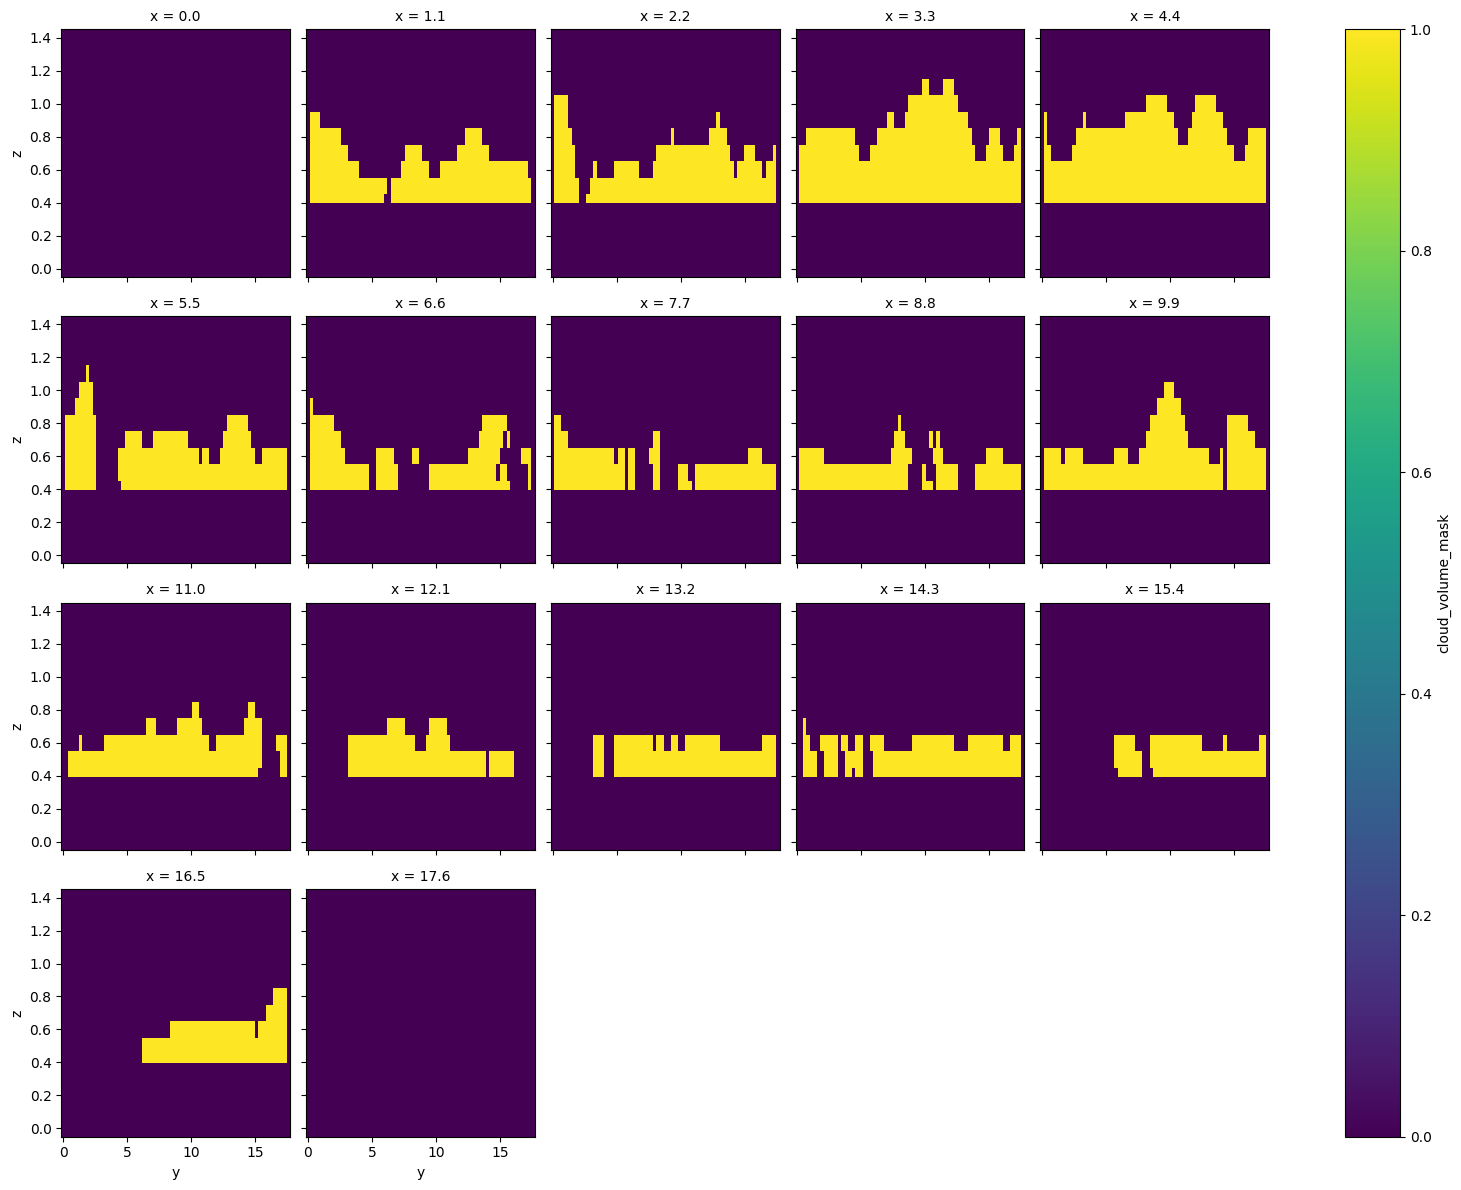

In [17]:
rte_grid.cloud_volume_mask.isel(x=slice(0,None,4)).plot(x='y', y='z', col='x', col_wrap=5)

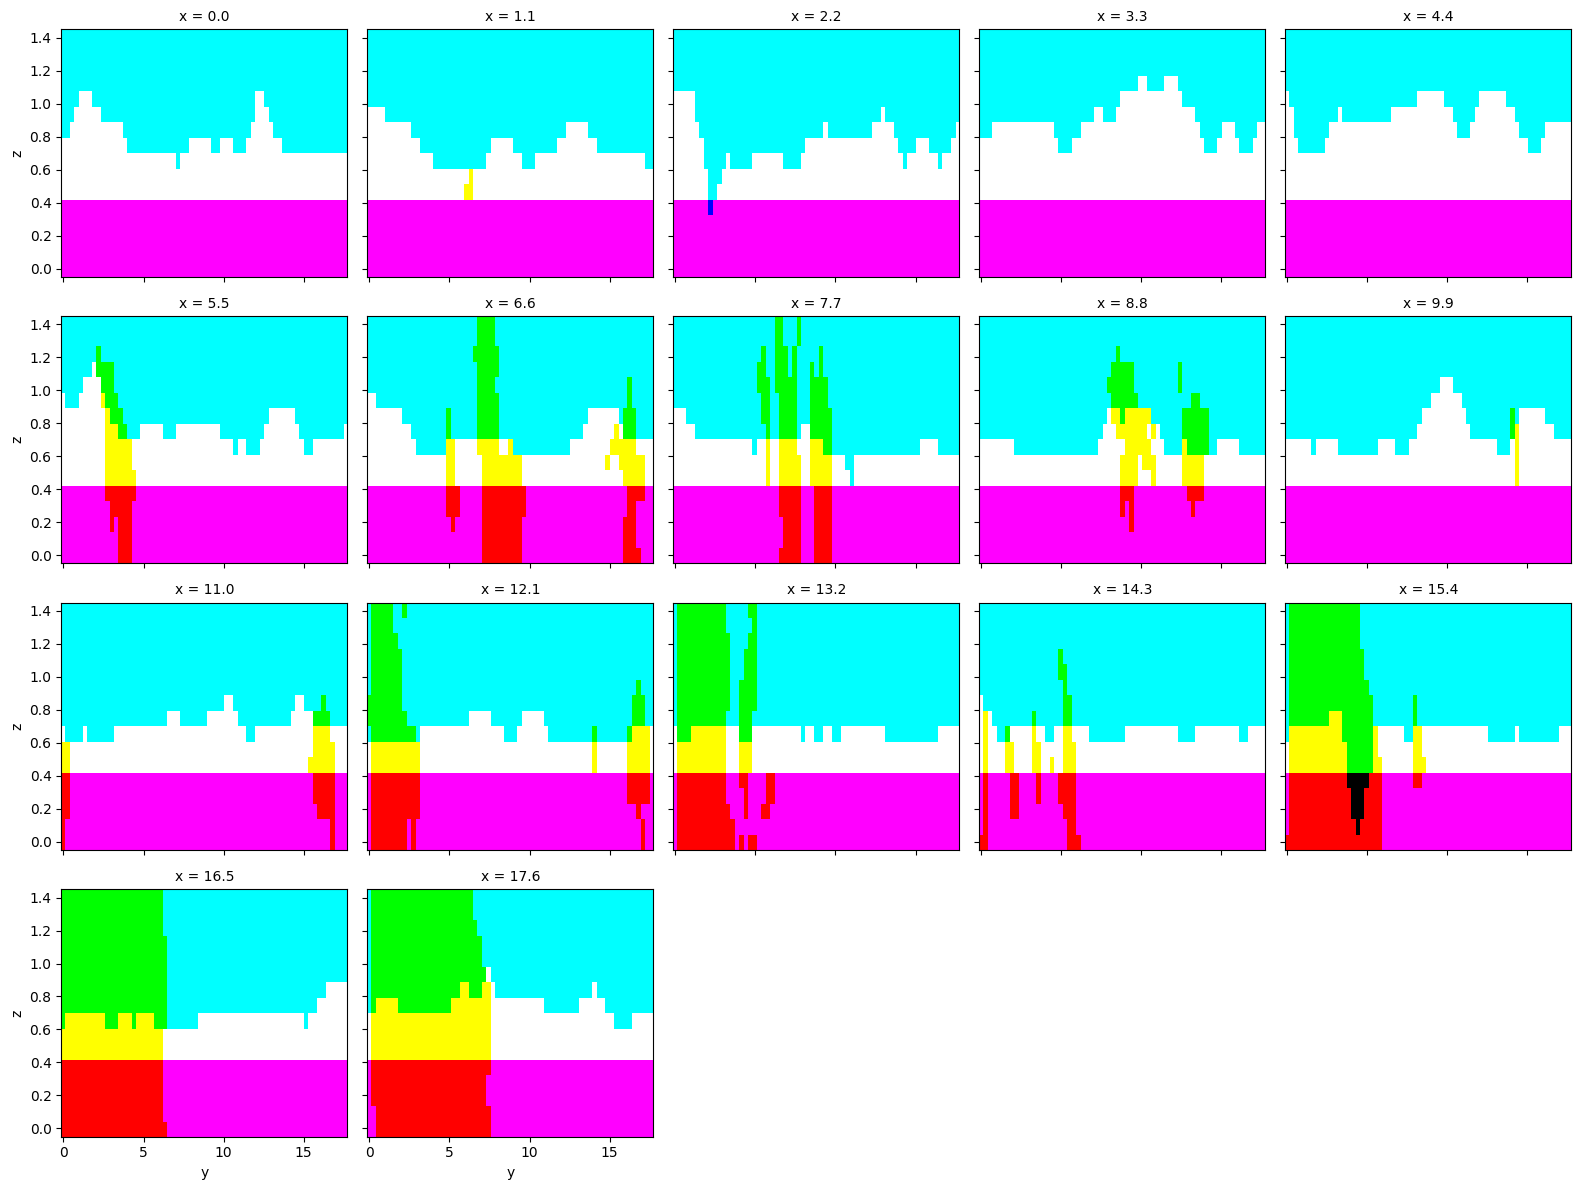

In [18]:
rte_grid.rbg_mask.isel(x=slice(0,None,4)).plot.imshow(x='y', y='z', col='x', col_wrap=5)